# Détection d'une figure : du simulateur à l'entraînement
Dataset synthétique → apprentissage → feature maps → prédiction + NMS.

In [ ]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

from src.dataset_generator_3 import make_example
from src.detector import Detector, STRIDE, predict
from src.visualize import show_images, show_feature_maps, show_detections
from src.detector import code
from src.train import evaluate, train

MODEL_SIZE = 64          # taille d'entrée utilisée à l'entraînement
assert MODEL_SIZE % STRIDE == 0   # la grille de feature maps fait MODEL_SIZE // STRIDE

## 1. Génération du dataset
On génère directement les images à la taille attendue par le modèle.

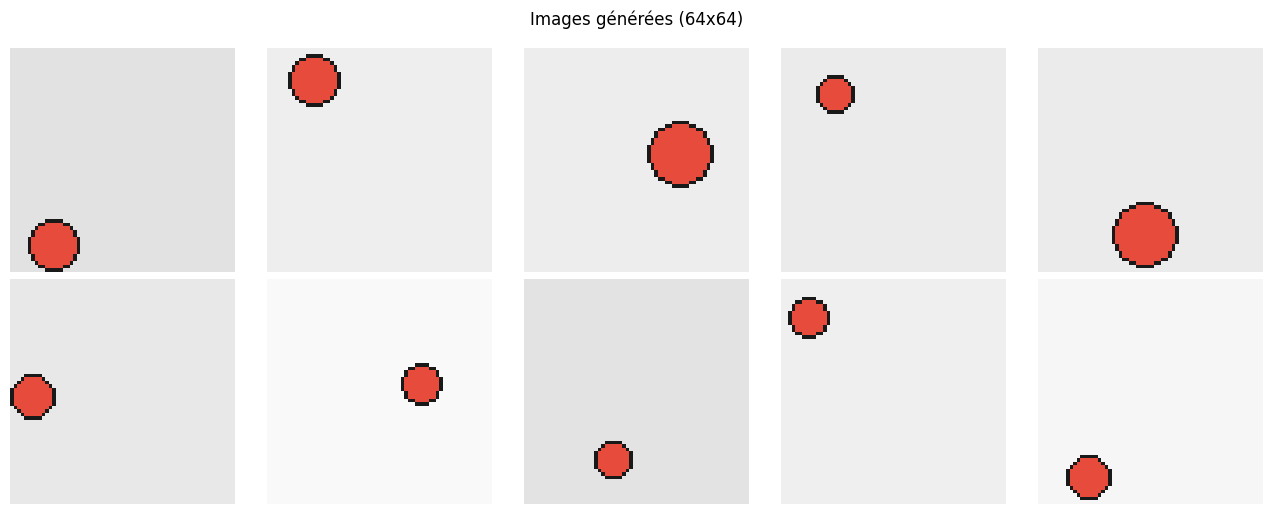

In [10]:
rng = random.Random(123)
pil_images = [make_example(MODEL_SIZE, "circle", rng)[0] for _ in range(10)]
show_images(pil_images, f"Images générées ({MODEL_SIZE}x{MODEL_SIZE})")

Les images sont déjà générées à la taille attendue par le détecteur (`MODEL_SIZE`×`MODEL_SIZE`, multiple du stride) : aucun redimensionnement, on les convertit simplement en tenseurs `(3, H, W)` normalisés dans [0, 1].

In [11]:
def to_tensor(image):
    return torch.from_numpy(np.asarray(image.convert("RGB"), dtype=np.float32).copy()).permute(2, 0, 1) / 255.0

images = torch.stack([to_tensor(im) for im in pil_images])
print(images.shape)

torch.Size([10, 3, 64, 64])


## 2. Génération d'un jeu de données d'entraînement plus grand
On génère 2 000 images pour l'entraînement et 400 images indépendantes pour la validation. Les étiquettes (en pixels) sont encodées en cibles `(5, G, G)`.

In [12]:

def make_dataset(count, seed):
    rng = random.Random(seed)
    dataset_images, targets = [], []
    for _ in range(count):
        image, label = make_example(MODEL_SIZE, "circle", rng)
        cx, cy, width, height = map(float, label.split())
        dataset_images.append(to_tensor(image))
        targets.append(code(cx, cy, width, height, size=MODEL_SIZE))
    return TensorDataset(torch.stack(dataset_images), torch.stack(targets))



## 3. Entraînement du modèle


In [13]:
TRAIN_SAMPLES = 2_00
VAL_SAMPLES = 40
BATCH_SIZE = 64
EPOCHS = 50

import tempfile
from datetime import datetime
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

# Les logs sont écrits hors du dossier synchronisé ownCloud (TensorBoard/TensorFlow
# n'y accède pas correctement : "runs/demo is not a directory").
LOG_ROOT = Path(tempfile.gettempdir()) / "tb_runs" / "demo"
LOG_ROOT.mkdir(parents=True, exist_ok=True)
print("Logs TensorBoard :", LOG_ROOT)

torch.manual_seed(0)
train_set = make_dataset(TRAIN_SAMPLES, seed=7)
val_set = make_dataset(VAL_SAMPLES, seed=8)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)

model = Detector()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
run_dir = LOG_ROOT / datetime.now().strftime('%Y%m%d-%H%M%S')
with SummaryWriter(log_dir=str(run_dir)) as writer:
    for epoch in range(1, EPOCHS + 1):
        mean_loss = train(model, train_loader, optimizer)
        val_iou, val_accuracy = evaluate(model, val_loader, MODEL_SIZE)
        writer.add_scalar("Loss/train", mean_loss, epoch)
        writer.add_scalar("IoU/validation", val_iou, epoch)
        writer.add_scalar("Accuracy/validation_IoU_gt_0.5", val_accuracy, epoch)
        print(f"epoch {epoch:2d}  loss {mean_loss:.4f}  "
              f"val IoU {val_iou:.3f}  IoU>0.5 {val_accuracy:.0%}")

model.eval();

Logs TensorBoard : C:\Temp\tb_runs\demo
epoch  1  loss 0.0291  val IoU 0.221  IoU>0.5 0%
epoch  2  loss 0.0207  val IoU 0.236  IoU>0.5 0%
epoch  3  loss 0.0175  val IoU 0.261  IoU>0.5 0%
epoch  4  loss 0.0152  val IoU 0.286  IoU>0.5 3%
epoch  5  loss 0.0137  val IoU 0.319  IoU>0.5 12%
epoch  6  loss 0.0122  val IoU 0.366  IoU>0.5 17%
epoch  7  loss 0.0114  val IoU 0.408  IoU>0.5 25%
epoch  8  loss 0.0101  val IoU 0.474  IoU>0.5 43%
epoch  9  loss 0.0092  val IoU 0.488  IoU>0.5 45%
epoch 10  loss 0.0084  val IoU 0.565  IoU>0.5 68%
epoch 11  loss 0.0078  val IoU 0.616  IoU>0.5 80%
epoch 12  loss 0.0072  val IoU 0.661  IoU>0.5 88%
epoch 13  loss 0.0064  val IoU 0.710  IoU>0.5 93%
epoch 14  loss 0.0058  val IoU 0.718  IoU>0.5 93%
epoch 15  loss 0.0054  val IoU 0.723  IoU>0.5 98%
epoch 16  loss 0.0051  val IoU 0.733  IoU>0.5 93%
epoch 17  loss 0.0046  val IoU 0.721  IoU>0.5 95%
epoch 18  loss 0.0043  val IoU 0.679  IoU>0.5 90%
epoch 19  loss 0.0039  val IoU 0.708  IoU>0.5 93%
epoch 20  loss

In [14]:
# Affiche la commande à lancer dans un terminal pour ouvrir TensorBoard dans le navigateur
import sys
print(f'& "{sys.executable}" -m tensorboard.main --logdir "{LOG_ROOT}" --port 6006')
print("Puis ouvrir http://localhost:6006")

& "c:\Users\ychasser\Documents\python-venvs\ml-dl\Scripts\python.exe" -m tensorboard.main --logdir "C:\Temp\tb_runs\demo" --port 6006
Puis ouvrir http://localhost:6006


## 4. Feature maps

torch.Size([10, 32, 8, 8])


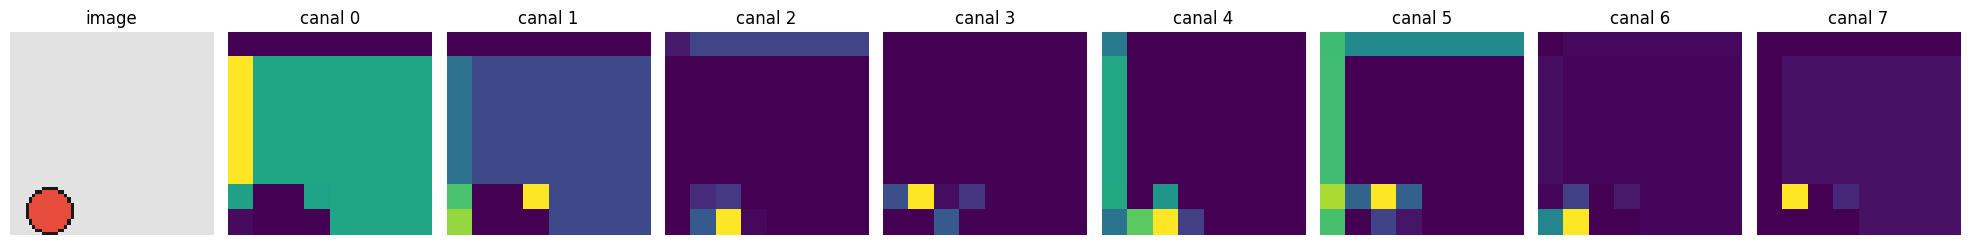

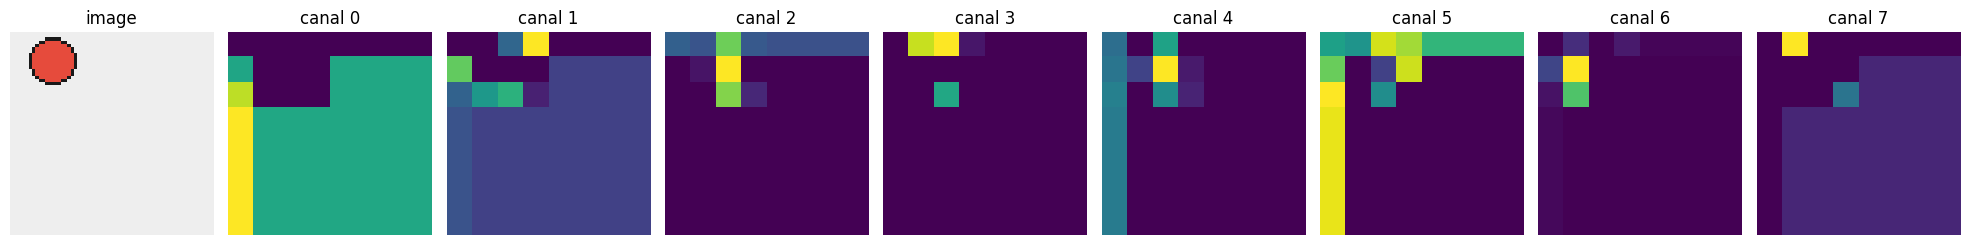

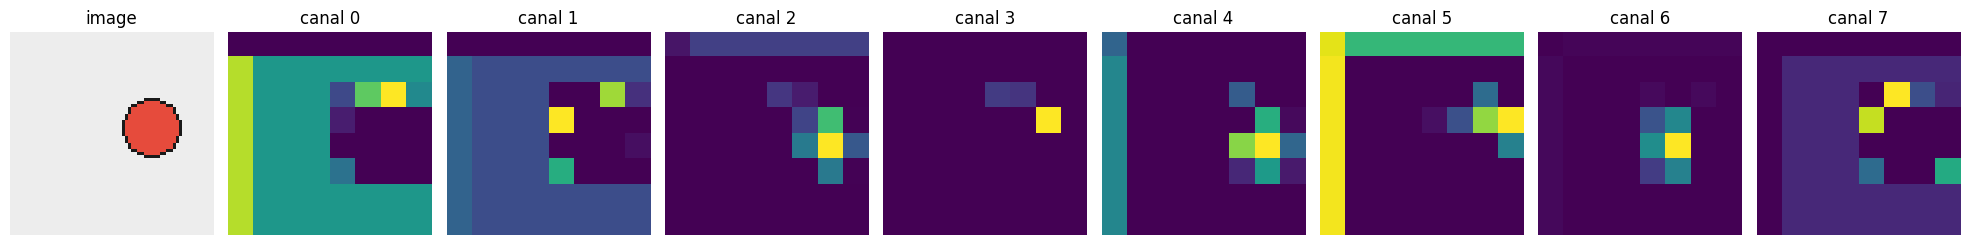

tensor([[ 0.2074,  0.1393, -0.1810],
        [ 0.0819, -0.0139, -0.0305],
        [-0.0679,  0.0457, -0.0755]], grad_fn=<SliceBackward0>)


In [15]:
with torch.no_grad():
    maps = model.feature_maps(images)   # (N, 32, 8, 8)
print(maps.shape)
for i in range(3):
    show_feature_maps(images[i], maps[i], n_maps=8)
    
print(model.backbone[0].weight[3, 0, :, :])

## 5. Prédiction, décodage et NMS : une boîte par image

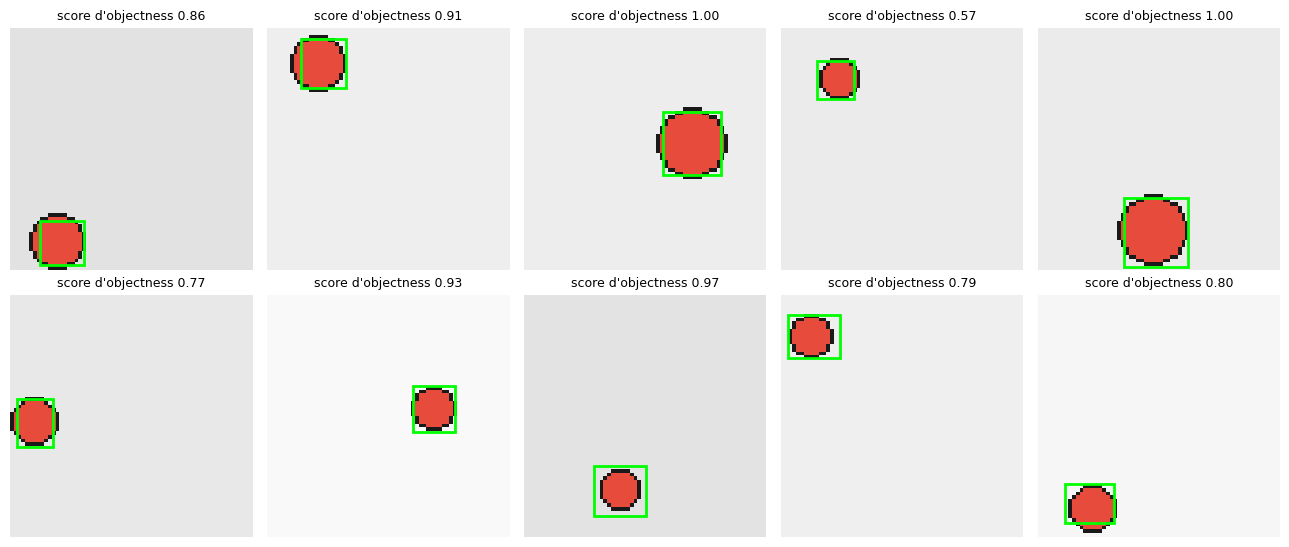

In [16]:
with torch.no_grad():
    logits = model(images)
results = [predict(l, MODEL_SIZE) for l in logits]
show_detections(list(images), [b for b, _ in results], [s for _, s in results])